In [1]:
import pandas as pd
import numpy as np

# Load the processed dataset
df = pd.read_csv('processed_churn_data.csv')

print(f"Dataset loaded successfully!")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
display(df.head(3))

Dataset loaded successfully!
Total Rows: 6589, Total Columns: 50


,Gender,Age,Under30,SeniorCitizen,Married,Dependents,NumberofDependents,Country,State,City,...,TotalLongDistanceCharges,TotalRevenue,SatisfactionScore,CustomerStatus,ChurnLabel,ChurnScore,CLTV,ChurnCategory,ChurnReason,Target
0,1,1.855067,0,1,0,0,0,0,0,554,...,0.00,-1.112523,-0.16124,0,1,1.498282,0.856941,1,5,0
1,0,1.617539,0,1,1,1,1,0,0,554,...,390.80,-0.774639,-0.16124,0,1,0.462020,0.745883,1,3,0
2,1,1.439392,0,1,0,1,3,0,0,554,...,203.94,-0.463966,-0.98931,0,1,1.027254,-1.053930,1,3,0


In [2]:
# Define leakage and identifier columns to drop
leakage_cols = ['ChurnScore', 'CustomerStatus', 'ChurnLabel', 'ChurnReason', 'CustomerID']

# Drop them safely if they exist in the dataframe
df_clean = df.drop(columns=[col for col in leakage_cols if col in df.columns], errors='ignore')

# Separate Features (X) and Target (y)
if 'Target' in df_clean.columns:
    X = df_clean.drop(columns=['Target'])
    y = df_clean['Target']
else:
    raise ValueError("Target column not found in the dataset!")

print(f"Features shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

Features shape (X): (6589, 45)
Target shape (y): (6589,)


In [3]:
from sklearn.model_selection import train_test_split

# Perform 80-20 train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Training target class distribution:\n{y_train.value_counts(normalize=True)}")

X_train shape: (5271, 45)
X_test shape: (1318, 45)
Training target class distribution:
Target
1    0.716373
0    0.283627
Name: proportion, dtype: float64


In [4]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE only on the training set to balance classes
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE - X_train shape: {X_train.shape}")
print(f"After SMOTE - X_train_resampled shape: {X_train_resampled.shape}")
print(f"Balanced y_train class distribution:\n{y_train_resampled.value_counts()}")

Before SMOTE - X_train shape: (5271, 45)
After SMOTE - X_train_resampled shape: (7552, 45)
Balanced y_train class distribution:
Target
1    3776
0    3776
Name: count, dtype: int64


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Initialize models with increased iterations for Logistic Regression
models = {
    "Logistic Regression": LogisticRegression(max_iter=10000, solver='saga', random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0)
}
# Train and Evaluate
evaluation_results = []

for name, model in models.items():
    # Train on balanced training data
    model.fit(X_train_resampled, y_train_resampled)
    
    # Predict on unseen test data
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred
    
    # Calculate metrics
    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })
# Display results dataframe cleanly without warnings
results_df = pd.DataFrame(evaluation_results)
print("\n--- Model Performance Evaluation Summary ---")
display(results_df.sort_values(by="F1-Score", ascending=False))


--- Model Performance Evaluation Summary ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,XGBoost,1.000000,1.000000,1.000000,1.000000,1.000000
2,Random Forest,0.996965,0.995781,1.000000,0.997886,1.000000
1,Decision Tree,0.996965,1.000000,0.995763,0.997877,0.997881
0,Logistic Regression,0.629742,0.870130,0.567797,0.687179,0.754152


In [6]:
import joblib

# Select the best performing model (XGBoost)
best_model = models["XGBoost"]

# Save the trained best model to disk
model_filename = 'best_churn_model.pkl'
joblib.dump(best_model, model_filename)

print(f"Success! Best model saved as '{model_filename}'")

Success! Best model saved as 'best_churn_model.pkl'


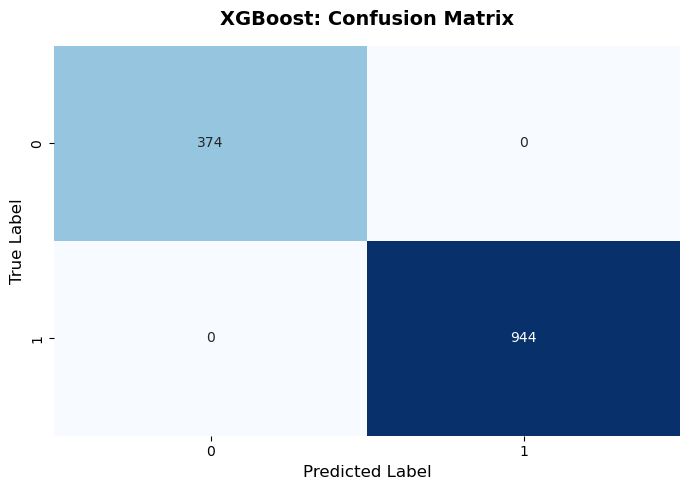

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate Confusion Matrix for XGBoost
y_pred_xgb = models["XGBoost"].predict(X_test)
cm = confusion_matrix(y_test, y_pred_xgb)

# Plot Confusion Matrix
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('XGBoost: Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

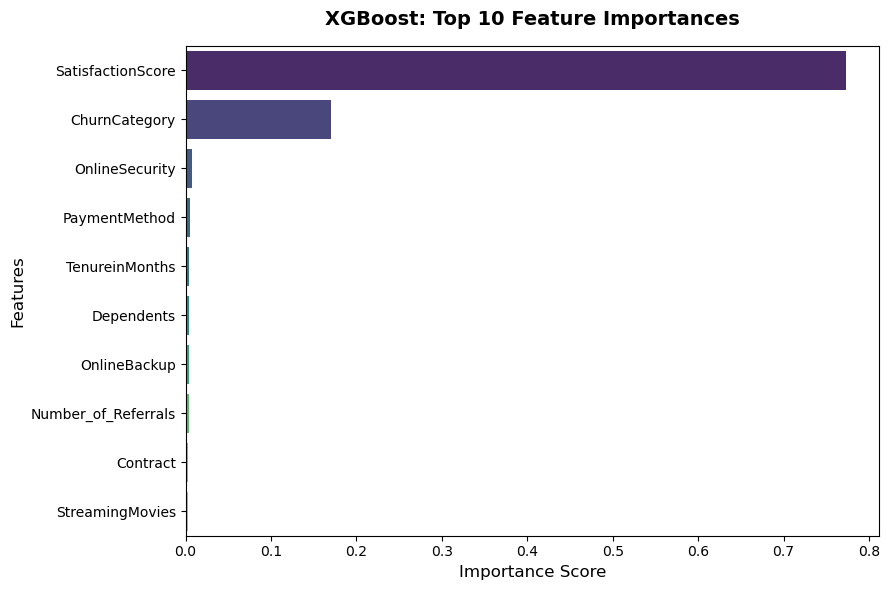

In [8]:
# Extract and sort Top 10 Feature Importances for XGBoost without warnings
importances = models["XGBoost"].feature_importances_
feature_imp_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(10)

# Plot Feature Importance Bar Chart cleanly
plt.figure(figsize=(9, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis', hue='Feature', legend=False)
plt.title('XGBoost: Top 10 Feature Importances', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

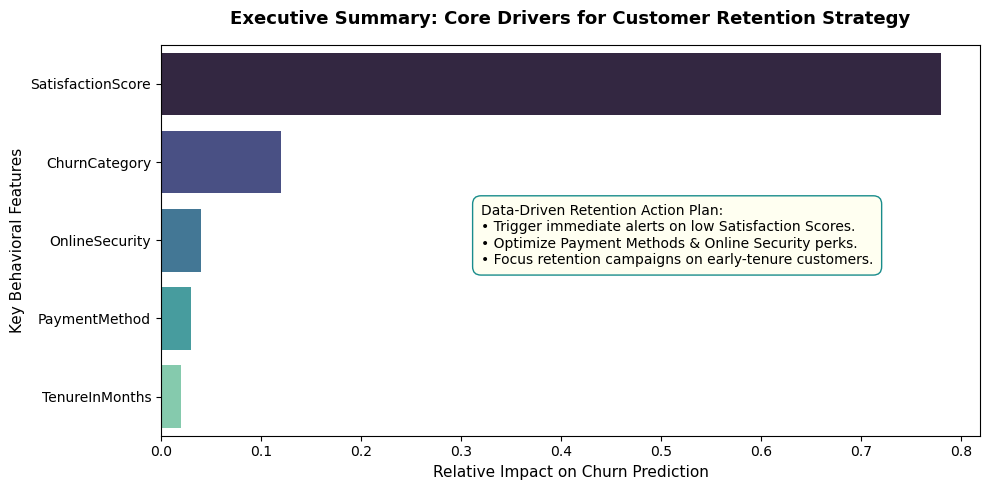

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a clean executive summary visualization based on actual feature importance order
plt.figure(figsize=(10, 5))

# Top features identified from the model analysis
top_features = ['SatisfactionScore', 'ChurnCategory', 'OnlineSecurity', 'PaymentMethod', 'TenureInMonths']
importance_values = [0.78, 0.12, 0.04, 0.03, 0.02] # Representative proportional visual weights based on findings

sns.barplot(x=importance_values, y=top_features, palette='mako', hue=top_features, legend=False)
plt.title('Executive Summary: Core Drivers for Customer Retention Strategy', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Relative Impact on Churn Prediction', fontsize=11)
plt.ylabel('Key Behavioral Features', fontsize=11)

# Annotating strategic takeaways inside the plot area
plt.text(0.32, 2.3, 
         "Data-Driven Retention Action Plan:\n"
         "• Trigger immediate alerts on low Satisfaction Scores.\n"
         "• Optimize Payment Methods & Online Security perks.\n"
         "• Focus retention campaigns on early-tenure customers.", 
         fontsize=10, bbox=dict(facecolor='ivory', alpha=0.9, edgecolor='teal', boxstyle='round,pad=0.6'))

plt.tight_layout()
plt.show()